In [31]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from itertools import product
import random

from pathlib import Path
import sys
# Agregar el path del directorio "code"
code_path = Path("../Code").resolve()
if str(code_path) not in sys.path:
    sys.path.insert(0, str(code_path))


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from TimeSeriesLib import MeanRollingForecast, LastRollingForecast, SarimaxRollingForecast

In [32]:
#TODO Pipeline que procese todo cammesa_data_x
df_a = pd.read_csv("../datasets/cammesa_data_A.csv",parse_dates=["fecha"])
df_b = pd.read_csv("../datasets/cammesa_data_B.csv",parse_dates=["fecha"])

df_combinado = pd.concat([df_a, df_b], ignore_index=True)

# 4. Eliminar duplicados basados ÚNICAMENTE en el campo 'fecha'
# 'keep="first"' conserva el primer registro encontrado (puedes usar 'keep="last"' si prefieres el de B)
df = df_combinado.drop_duplicates(subset=["fecha"], keep="first")

# 5. Ordenar por fecha para mantener la coherencia temporal
df = df.sort_values(by="fecha").reset_index(drop=True)

print(f"Filas originales A: {len(df_a)}, B: {len(df_b)}")
print(f"Filas combinadas sin duplicados: {len(df)}")


Filas originales A: 64159, B: 74293
Filas combinadas sin duplicados: 82967


In [33]:
df = df[["demanda", "fecha"]]

In [34]:
#Evitemos el warning de zona horaria
df['fecha'] = pd.to_datetime(df['fecha']).dt.tz_localize(None)
#agrupemos
df = (
    #df.groupby(df['fecha'].dt.to_period('W-MON'))['demanda'].mean().reset_index()
    df.groupby(df['fecha'].dt.to_period('D'))['demanda'].mean().reset_index()
)


In [35]:
df["demanda"] = df["demanda"] / 100

In [36]:
df.shape

(289, 2)

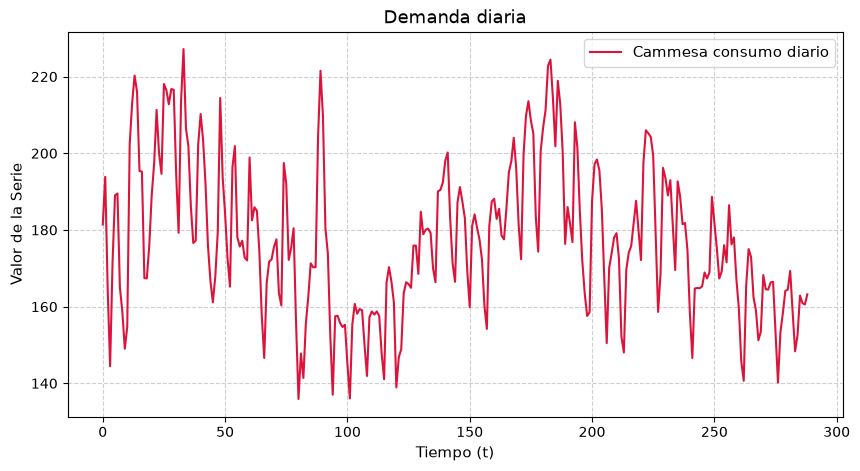

In [37]:
plt.figure(figsize=(10, 5))
plt.plot(df["demanda"], label=f'Cammesa consumo diario', color='crimson', linewidth=1.5)
plt.title('Demanda diaria', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [38]:
df.shape

(289, 2)

¿Es estacionaria?

In [39]:
ADF_result = adfuller(df["demanda"], result_object=False) #result_object=False para silenciar warning de deprecado 2027
#print(f'ADF Statistic: {ADF_result[0]}')
print(f'p-value: {ADF_result[1]}')

p-value: 0.18295021144225004


p-value>0.05, diferenciemos.

In [40]:
df_diff = df.copy()
df_diff["diff"] = df['demanda'].diff()
df_diff = df_diff.dropna(subset=["diff"]).reset_index(drop=True)

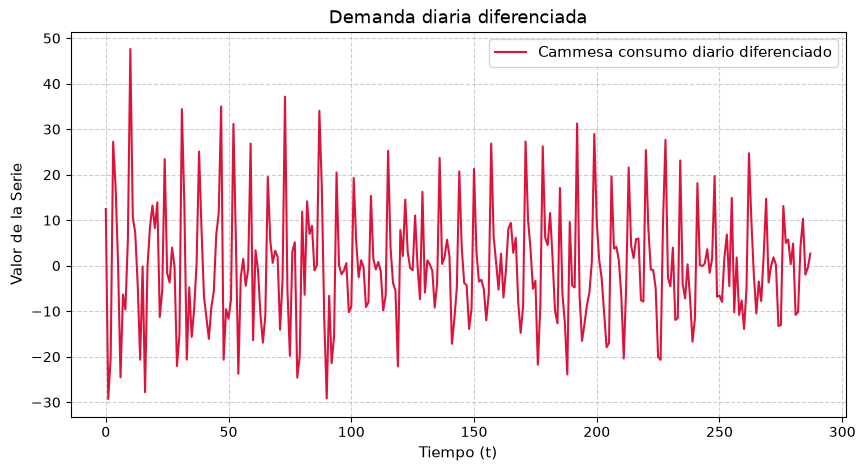

In [41]:
plt.figure(figsize=(10, 5))
plt.plot(df_diff["diff"], label=f'Cammesa consumo diario diferenciado', color='crimson', linewidth=1.5)
plt.title('Demanda diaria diferenciada', fontsize=13)
plt.xlabel('Tiempo (t)', fontsize=11)
plt.ylabel('Valor de la Serie', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


Análisis de correlaciones

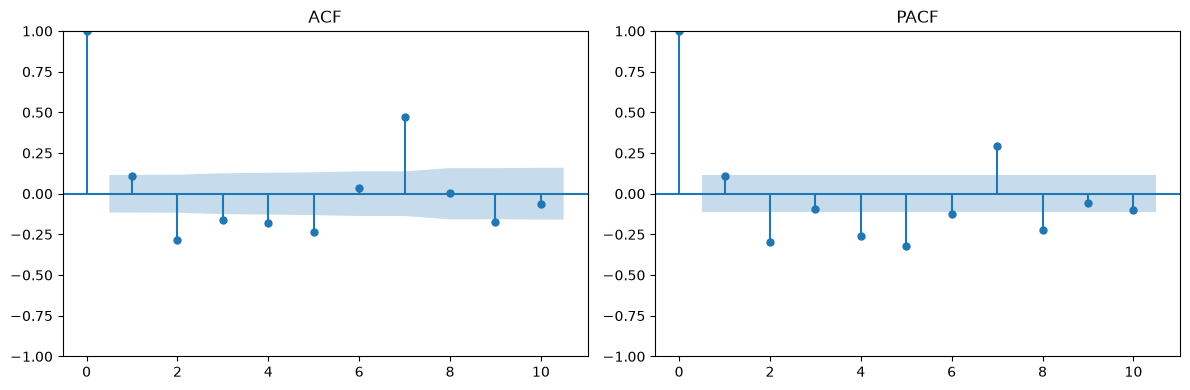

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# ACF
plot_acf(df_diff["diff"], ax=axes[0], lags=10, alpha=0.05)
axes[0].set_title("ACF")

# PACF
plot_pacf(df_diff["diff"], ax=axes[1], lags=10, alpha=0.05, method="ywm")
axes[1].set_title("PACF")

plt.tight_layout()
plt.show()

"no sharp cutoff"

Ahora los modelos ¿Puedo ganar?

In [44]:
train_percent = 0.8
result = {}
result["window"] = []
result["mean"] = []
result["last"] = []
result["sarimax"] = []

for window in range(1,20):
    estimators = {}
    estimators["mean"]      = MeanRollingForecast(window=window, train_percent=train_percent, mean_steps=5)
    estimators["last"]      = LastRollingForecast(window=window, train_percent=train_percent)
    estimators["sarimax"]   = SarimaxRollingForecast(window=window, train_percent=train_percent, order=(1,1,0)) #diferencia 1 segun analizamos
    result["window"].append(window) 
    for k, v in estimators.items():
        v.backtest(df["demanda"])
        result[k].append(v.score())
           

df_r = pd.DataFrame(result)

Error absoluto medio en función del horizonte de pronostico. Es dificil ganarle al "last" con ventanas cortas, a medida que avanzamos la media se va volviendo mas fuerte.

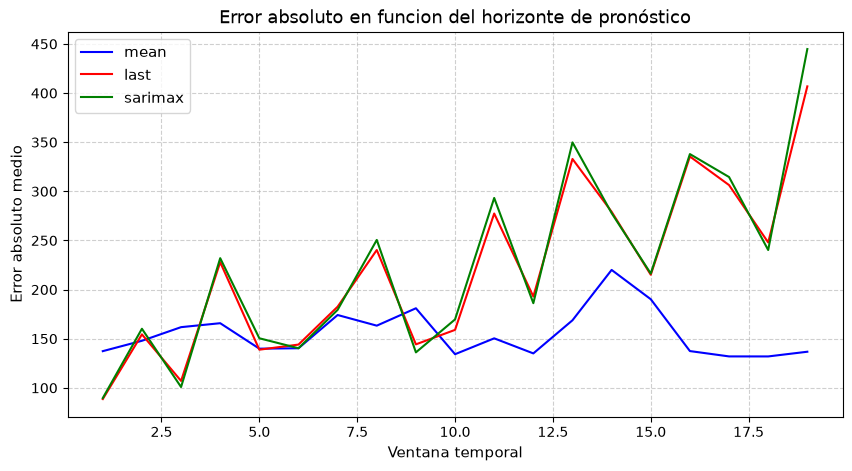

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(df_r["window"], df_r["mean"], label=f'mean', color='blue', linewidth=1.5)
plt.plot(df_r["window"], df_r["last"], label=f'last', color='red', linewidth=1.5)
plt.plot(df_r["window"], df_r["sarimax"], label=f'sarimax', color='green', linewidth=1.5)

plt.title('Error absoluto en funcion del horizonte de pronóstico', fontsize=13)
plt.xlabel('Ventana temporal', fontsize=11)
plt.ylabel('Error absoluto medio', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Probar con window = 1

Mean: 137.36, Last: 88.61, MA: 89.61


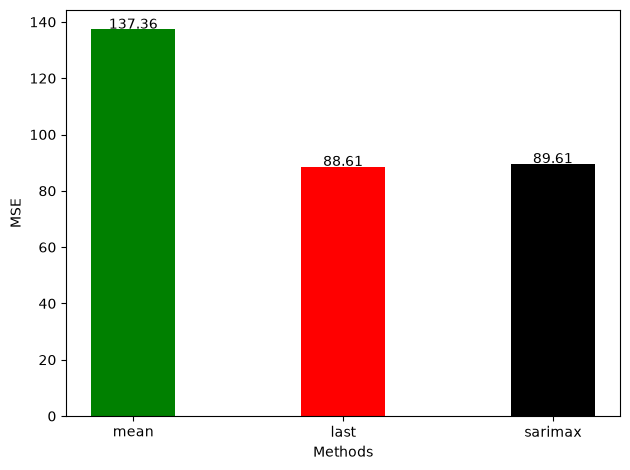

In [48]:
window = 1
estimators = {}
estimators["mean"]      = MeanRollingForecast(window=window, train_percent=train_percent, mean_steps=5)
estimators["last"]      = LastRollingForecast(window=window, train_percent=train_percent)
estimators["sarimax"]   = SarimaxRollingForecast(window=window, train_percent=train_percent, order=(1,1,0)) #diferencia 1 segun analizamos
result["window"].append(window) 
for k, v in estimators.items():
    y_pred = v.backtest(df["demanda"])
    df[k] = y_pred
    result[k].append(v.score())

print("Mean: {:.2f}, Last: {:.2f}, MA: {:.2f}".format(estimators["mean"].score(), estimators["last"].score(), estimators["sarimax"].score()))
fig, ax = plt.subplots()
x = ['mean', 'last', 'sarimax']
y = [estimators["mean"].score(), estimators["last"].score(), estimators["sarimax"].score()]
ax.bar(x, y, width=0.4, color=['g', 'r', 'k'])
ax.set_xlabel('Methods')
ax.set_ylabel('MSE')
#ax.set_ylim(0, 5)
for index, value in enumerate(y):
    plt.text(x=index, y=value+0.25, s=str(round(value, 2)), ha='center')
plt.tight_layout()
plt.show()

Veamos las predicciones con una ventana de n

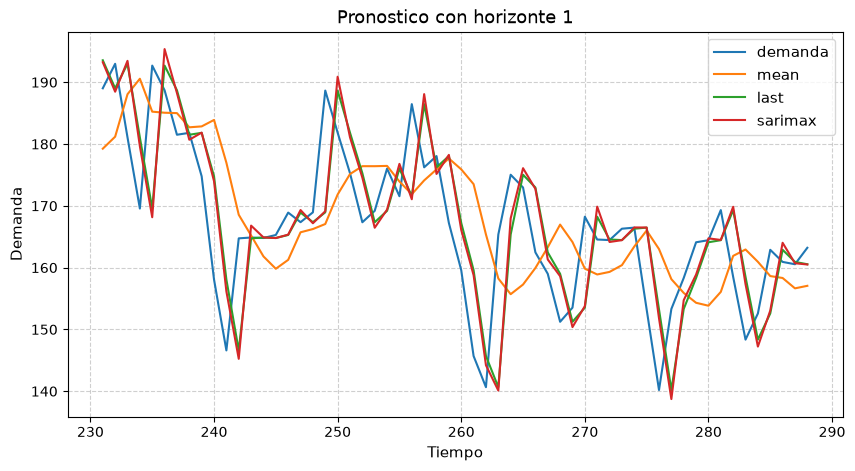

In [49]:
df_plot = df[["demanda", "mean", "last", "sarimax"]]
plt.figure(figsize=(10, 5))
for col in df_plot.columns:
    plt.plot(df_plot[y_pred.index[0]:].index, df_plot[y_pred.index[0]:][col], label=f'{col}', linewidth=1.5)

plt.title(f'Pronostico con horizonte {window}', fontsize=13)
plt.xlabel('Tiempo', fontsize=11)
plt.ylabel('Demanda', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Last tiene mejor rendimiento para una ventana de 1...  
Es posible que tengamos oportunidades de mejora.